# Chapter 8: Tree-Based Algorithms and Ensemble Methods

## 1. Ringkasan Bab
Model berbasis pohon keputusan (*decision trees*) dan metode ansambel (*ensemble methods*) merupakan kelompok algoritma yang sangat populer karena kemampuannya memodelkan hubungan non-linier yang kompleks tanpa memerlukan transformasi data yang rumit.

Poin-poin inti yang dipelajari pada bab ini meliputi:
- **Pohon Keputusan (Decision Trees)**: Pemisahan biner rekursif berdasarkan kriteria kemurnian seperti Gini Impurity dan Information Gain (Entropy).
- **Bagging & Random Forests**: Pengurangan variansi melalui agregasi banyak pohon yang dilatih pada sampel acak (*bootstrap sampling*) serta pemilihan fitur secara acak.
- **Boosting (Gradient Boosting)**: Pembangunan model ansambel bertahap di mana setiap pohon baru ditambahkan untuk meminimalkan sisa kesalahan (*residual error*) dari pohon-pohon sebelumnya.
- **Penyetelan Hyperparameter Pohon**: Pengendalian overfitting melalui pembatasan kedalaman (`max_depth`), jumlah sampel minimum daun (`min_samples_leaf`), serta rasio fitur (`max_features`).
- **Komparasi Model Ansambel**: Evaluasi perbedaan trade-off antara model individual, Bagging, dan Boosting pada data uji.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings

np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Modul dan pustaka Chapter 8 berhasil dimuat.")

Modul dan pustaka Chapter 8 berhasil dimuat.


## 2. Decision Tree Classifier

Decision Tree mempartisi ruang fitur ke dalam wilayah persegi panjang menggunakan aturan berjenjang (*if-else rules*).

Kriteria pemisahan utama:
1. **Gini Impurity**:
   $$G = 1 - \sum_{i=1}^{C} p_i^2$$
2. **Entropy (Information Gain)**:
   $$H = -\sum_{i=1}^{C} p_i \log_2(p_i)$$

Pohon keputusan tanpa batasan parameter cenderung tumbuh sangat dalam hingga menghafal data latihan (*overfitting*). Oleh karena itu, teknik pemangkasan (*pruning*) atau pembatasan parameter awal (*pre-pruning*) seperti `max_depth` sangat diperlukan.

In [2]:
# Memuat data klasifikasi
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
feature_names = cancer.feature_names
target_names = cancer.target_names

# Pembagian data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=2024, stratify=y
)

# Membangun model Decision Tree dengan pembatasan kedalaman
dt_clf = DecisionTreeClassifier(max_depth=4, random_state=2024)
dt_clf.fit(X_train, y_train)

y_pred_dt = dt_clf.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

print(f"Akurasi Decision Tree (max_depth=4): {acc_dt:.4f} ({acc_dt*100:.2f}%)")

Akurasi Decision Tree (max_depth=4): 0.9580 (95.80%)


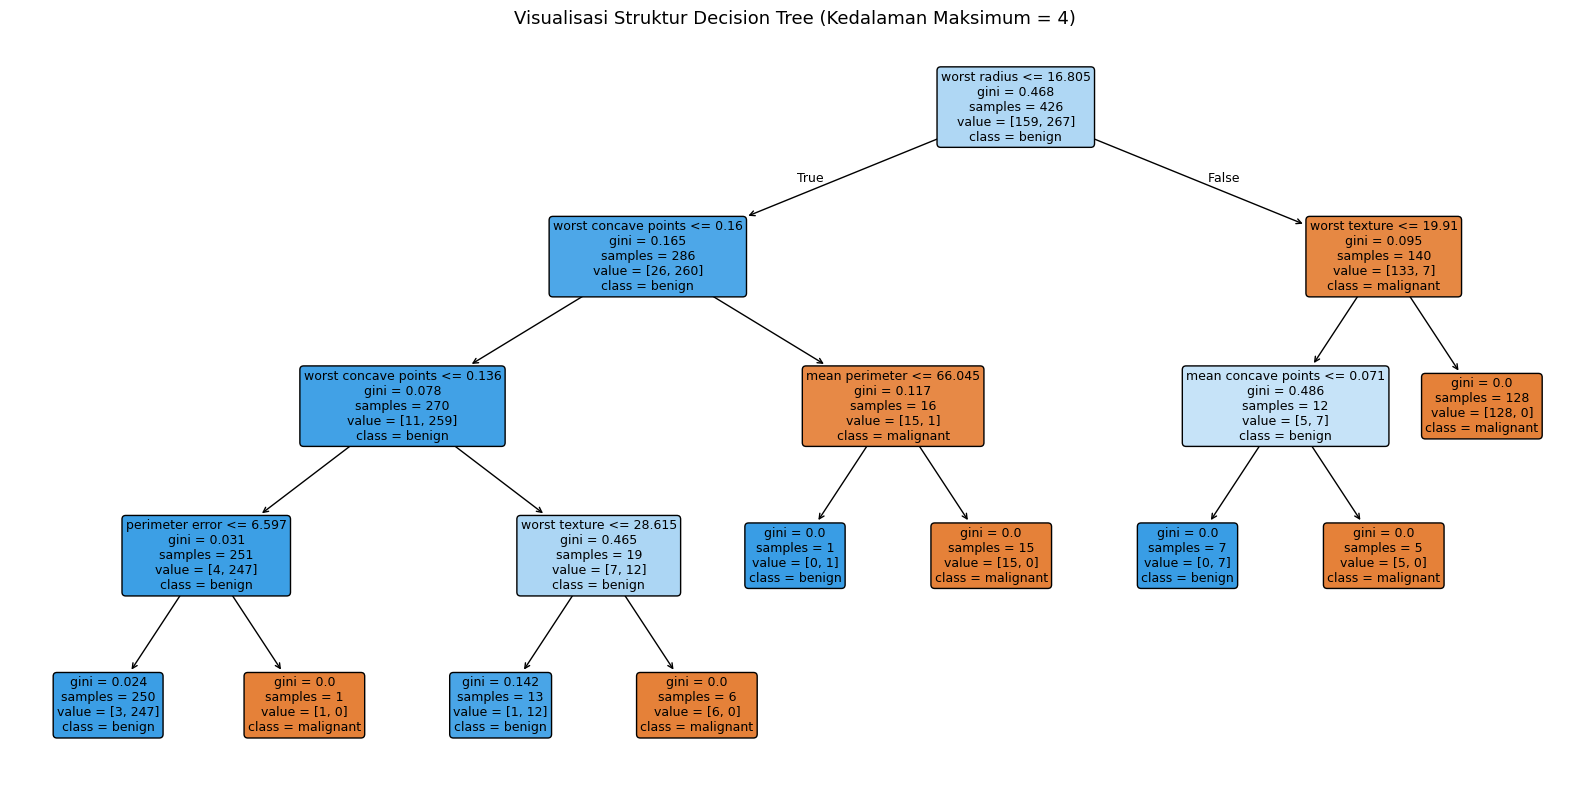

In [3]:
# Visualisasi Struktur Pohon Keputusan
plt.figure(figsize=(16, 8))
plot_tree(
    dt_clf,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Visualisasi Struktur Decision Tree (Kedalaman Maksimum = 4)", fontsize=13)
plt.tight_layout()
plt.show()

## 3. Random Forests & Bagging

Random Forest mengatasi kelemahan variansi tinggi pada pohon keputusan tunggal dengan menggabungkan dua teknik acak:
1. **Bootstrap Aggregating (Bagging)**: Melatih setiap pohon pada himpunan bagian acak dari data latih dengan pengembalian (*sampling with replacement*).
2. **Feature Subsampling**: Pada tiap titik percabangan, algoritma hanya mempertimbangkan sebagian fitur acak (biasanya $\sqrt{p}$) agar korelasi antar-pohon berkurang.

Hasil inferensi akhir diperoleh melalui voting mayoritas untuk klasifikasi atau rata-rata untuk regresi.

In [4]:
# Melatih Model Random Forest
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    random_state=2024
)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Random Forest (100 Trees): {acc_rf:.4f} ({acc_rf*100:.2f}%)")

Akurasi Random Forest (100 Trees): 0.9580 (95.80%)


## 4. Gradient Boosting Machines (GBM)

Berbeda dengan Random Forest yang membangun pohon secara paralel dan independen, Gradient Boosting membangun pohon secara sekuensial:
1. Pohon pertama dibuat untuk menghasilkan tebakan awal.
2. Setiap pohon berikutnya dilatih untuk memprediksi gradien negatif dari fungsi kerugian (*pseudo-residuals*) yang ditinggalkan oleh ansambel sebelumnya.
3. Kontribusi tiap pohon diperkecil oleh tingkat pembelajaran (*learning rate*) $\eta \in (0, 1]$ guna mencegah adaptasi berlebih terhadap derau data.

In [5]:
# Melatih Model Gradient Boosting
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=2024
)
gb_clf.fit(X_train, y_train)

y_pred_gb = gb_clf.predict(X_test)
acc_gb = accuracy_score(y_test, y_pred_gb)

print(f"Akurasi Gradient Boosting: {acc_gb:.4f} ({acc_gb*100:.2f}%)")

Akurasi Gradient Boosting: 0.9580 (95.80%)


## 5. Kepentingan Fitur (Feature Importances)

Model berbasis pohon menyediakan atribut `.feature_importances_` yang mengukur seberapa banyak suatu fitur berkontribusi dalam menurunkan kriteria ketidakmurnian (Gini Impurity) di seluruh percabangan pohon.

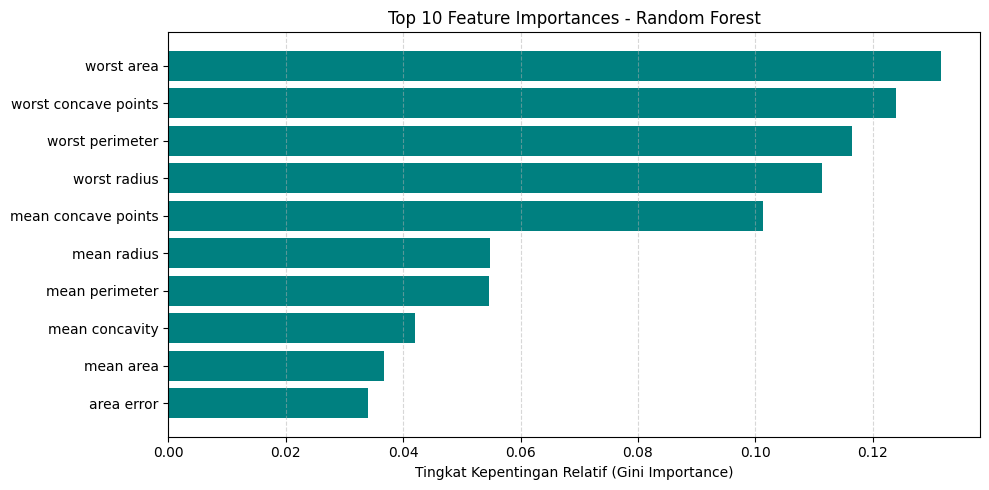

In [6]:
# Visualisasi 10 Fitur Terpenting Berdasarkan Random Forest
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1][:10]

plt.figure(figsize=(10, 5))
plt.barh(range(10), importances[indices][::-1], align='center', color='teal')
plt.yticks(range(10), [feature_names[i] for i in indices][::-1])
plt.xlabel('Tingkat Kepentingan Relatif (Gini Importance)')
plt.title('Top 10 Feature Importances - Random Forest')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Komparasi Kinerja Model

Bagian ini menyajikan perbandingan metrik evaluasi antara Decision Tree tunggal, Random Forest, dan Gradient Boosting pada himpunan data uji yang sama.

In [7]:
# Perbandingan Performa Model
models = {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb
}

comparison_data = []
for name, preds in models.items():
    comparison_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds)
    })

comparison_df = pd.DataFrame(comparison_data).sort_values('Accuracy', ascending=False)
display(comparison_df.style.format({'Accuracy': '{:.4f}'}))

,Model,Accuracy
0,Decision Tree,0.9580
1,Random Forest,0.9580
2,Gradient Boosting,0.9580


## 7. Analisis dan Kesimpulan
1. **Reduksi Variansi Ansambel**: Model Random Forest dan Gradient Boosting menunjukkan akurasi generalisasi yang lebih tinggi serta lebih stabil dibandingkan Decision Tree tunggal yang rentan terhadap variansi tinggi.
2. **Karakteristik Pembelajaran**: Random Forest menurunkan kesalahan melalui pengurangan variansi (*variance reduction*), sedangkan Gradient Boosting mengoptimalkan kinerja melalui pengurangan bias secara bertahap (*bias reduction*).
3. **Interpretasi Model**: Atribut kepentingan fitur memberikan gambaran transparan mengenai variabel mana yang paling berpengaruh terhadap pengambilan keputusan prediksi model.